# Modeling Universe Definition & Temporal Splits

This notebook establishes the final modeling universe by merging SPX options with interpolated FRED risk-free rates, inverting Black-Scholes implied volatilities via Newton-Raphson, filtering numerical outliers, generating 3D surfaces of theoretical IV, and constructing chronological train/tuning/test partitions with embargo gaps.

**Author:** Sérgio da Cunha Sobral  
**Date:** July 2025


### 1. Library Imports


In [1]:
import pandas as pd
import numpy as np
import os
import holidays
from py_vollib.black_scholes.implied_volatility import implied_volatility
import matplotlib.pyplot as plt
import seaborn as sns
import os, json

### 2. Core Paths & Configuration


In [2]:
# Core Paths and Configuration
dir_input    = "02_data/raw/"
dir_tratados = "02_data/processed/"
DIR_GRAFICOS = "04_outputs/01_figures/03_rates_individual/"

os.makedirs(DIR_GRAFICOS, exist_ok=True)
os.makedirs(dir_tratados, exist_ok=True)

ficheiro_input = os.path.join(dir_input, "InputData_v0.02.parquet")
taxas_juro     = os.path.join(dir_tratados, "df_IR.parquet")

# Output Parquet Splits
ficheiro_universo        = os.path.join(dir_tratados, "Universo_Modelizacao_v1.00.parquet")
ficheiro_inner_train     = os.path.join(dir_tratados, "df_inner_train.parquet")
ficheiro_inner_tunning   = os.path.join(dir_tratados, "df_inner_tunning.parquet")
ficheiro_train_full      = os.path.join(dir_tratados, "df_train_full.parquet")
ficheiro_test_puro       = os.path.join(dir_tratados, "df_test_puro.parquet")
ficheiro_meta_splits     = "02_data/splits_meta.json"


### 3. Load Auxiliary Utilities


Palete de Cores:
azul1: #11469b
azul2: #2063c0
azul3: #5a90e7
cinza1: #777777
cinza2: #AAAAAA
cinza3: #bbbbbb
preto: #000000
branco: #ffffff

Estilos de Linha:
contínua: -
tracejada: --
ponto-traço: -.
pontilhada: :
contínua2: -
tracejada2: --
ponto-traço2: -.
pontilhada2: :


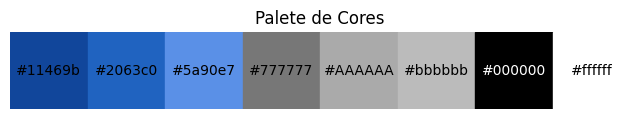

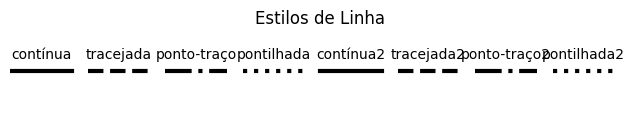

In [3]:
%run "03_notebooks/00_utils/01_auxiliary_functions.ipynb"


### 4. Data Ingestion


In [4]:
# Carregamento do ficheiro parquet
df_1 = pd.read_parquet(ficheiro_input)
df_IR = pd.read_parquet(taxas_juro)

# Verificação inicial
print(f"✔️ Shape: {df_1.shape}")
display(df_1.head())

print(f"✔️ Shape: {df_IR.shape}")
display(df_IR.tail())

✔️ Shape: (15144974, 18)


,quote_date,root,expiration,strike,option_type,bid_size_1545,ask_size_1545,bid_1545,ask_1545,underlying_bid_1545,underlying_ask_1545,bid_size_eod,ask_size_eod,bid_eod,ask_eod,underlying_bid_eod,underlying_ask_eod,open_interest
0,2009-01-02,JXA,2009-01-02,750.0,C,0,0,0.0,0.0,933.41,933.41,0,0,0.0,0.0,931.8,931.8,0
1,2009-01-02,JXA,2009-01-02,750.0,P,0,0,0.0,0.0,933.41,933.41,0,0,0.0,0.0,931.8,931.8,1751
2,2009-01-02,JXA,2009-01-02,775.0,C,0,0,0.0,0.0,933.41,933.41,0,0,0.0,0.0,931.8,931.8,0
3,2009-01-02,JXA,2009-01-02,775.0,P,0,0,0.0,0.0,933.41,933.41,0,0,0.0,0.0,931.8,931.8,458
4,2009-01-02,JXA,2009-01-02,800.0,C,0,0,0.0,0.0,933.41,933.41,0,0,0.0,0.0,931.8,931.8,0


✔️ Shape: (2583, 5)


,observation_date,DGS1MO,DGS3MO,DGS6MO,DGS1
2578,2019-04-24,0.0242,0.0244,0.0246,0.0242
2579,2019-04-25,0.0243,0.0243,0.0246,0.0242
2580,2019-04-26,0.0242,0.0242,0.0246,0.0241
2581,2019-04-29,0.0245,0.0244,0.0247,0.0242
2582,2019-04-30,0.0243,0.0243,0.0246,0.0239


### 5. Selection of Relevant Variables


In [5]:
# Seleção de Variáveis Relevantes
colunas_relevantes = [
    "quote_date",
    "expiration",
    "strike",
    "option_type",
    'bid_size_1545',
    'ask_size_1545',
    'bid_1545',
    'ask_1545',
    'underlying_bid_1545',
    'underlying_ask_1545'
]


df_2 = df_1[colunas_relevantes].copy()
print(f"Colunas selecionadas: {df_2.columns.tolist()}")
df_2.head()
print(f"✔️ Shape: {df_2.shape}")

Colunas selecionadas: ['quote_date', 'expiration', 'strike', 'option_type', 'bid_size_1545', 'ask_size_1545', 'bid_1545', 'ask_1545', 'underlying_bid_1545', 'underlying_ask_1545']
✔️ Shape: (15144974, 10)


### 6. Feature Engineering (Moneyness & Log-Moneyness)


In [6]:
# Step 1: Create auxiliary features from raw data
df_3 = df_2.copy()

# Garantir que datas estão em datetime
for col in ["quote_date", "expiration"]:
    df_3[col] = pd.to_datetime(df_3[col])

# 1. T_days: diferença entre expiration e quote_date em dias
df_3["T_days"] = (df_3["expiration"] - df_3["quote_date"]).dt.days

# 2. T: maturidade em anos
df_3["T"] = df_3["T_days"] / 365

# 3. option_price: média entre bid_1545 e ask_1545
df_3["option_price"] = (df_3["bid_1545"] + df_3["ask_1545"]) / 2

# 4. S: preço do subjacente (média de underlying_bid_1545 e underlying_ask_1545)
df_3["S"] = (df_3["underlying_bid_1545"] + df_3["underlying_ask_1545"]) / 2

# 5. moneyness linear: K/S
df_3["moneyness"] = df_3["strike"] / df_3["S"]

# 6. log_moneyness: log(K/S)
df_3["log_moneyness"] = np.log(df_3["strike"] / df_3["S"])

# 7. Normalizar option_type e criar variável binária
df_3["option_type"] = df_3["option_type"].str.lower().map({"c": "c", "call": "c", "p": "p", "put": "p"})
tipos_unicos = df_3["option_type"].unique()
if not set(tipos_unicos).issubset({"c", "p"}):
    raise ValueError(f"Valores inesperados em option_type: {tipos_unicos}")
df_3["option_is_call"] = (df_3["option_type"] == "c").astype(int)

# 8. Ordenar colunas principais para facilitar análise/modelagem
colunas_ordenadas = [
    "option_type", "option_is_call", "quote_date", "expiration", "T_days", "T", "strike", "S", "option_price",
    "bid_1545", "ask_1545", "underlying_bid_1545", "underlying_ask_1545",
     "moneyness", "log_moneyness", "bid_size_1545", "ask_size_1545"
 ]
df_3 = df_3[[col for col in colunas_ordenadas if col in df_3.columns]]

print(df_3.head())

  option_type  option_is_call quote_date expiration  T_days    T  strike  \
0           c               1 2009-01-02 2009-01-02       0  0.0   750.0   
1           p               0 2009-01-02 2009-01-02       0  0.0   750.0   
2           c               1 2009-01-02 2009-01-02       0  0.0   775.0   
3           p               0 2009-01-02 2009-01-02       0  0.0   775.0   
4           c               1 2009-01-02 2009-01-02       0  0.0   800.0   

        S  option_price  bid_1545  ask_1545  underlying_bid_1545  \
0  933.41           0.0       0.0       0.0               933.41   
1  933.41           0.0       0.0       0.0               933.41   
2  933.41           0.0       0.0       0.0               933.41   
3  933.41           0.0       0.0       0.0               933.41   
4  933.41           0.0       0.0       0.0               933.41   

   underlying_ask_1545  moneyness  log_moneyness  bid_size_1545  ask_size_1545  
0               933.41   0.803505      -0.218771     

### 7. Liquidity & Maturity Filtering Criteria


In [7]:
# Aplicação dos filtros de liquidez e maturidade a partir de df_3
shapes_resumo = []
shapes_resumo.append(["Original", df_3.shape[0], df_3.shape[1]])

# Filtro de liquidez: bid_size_1545 > 0 e ask_size_1545 > 0
df_4 = df_3[(df_3["bid_size_1545"] > 0) & (df_3["ask_size_1545"] > 0)].copy()
shapes_resumo.append(["Liquidez", df_4.shape[0], df_4.shape[1]])

# Filtro de maturidade: T_days >= 7 e T_days <= 365
df_4 = df_4[(df_4["T_days"] >= 7) & (df_4["T_days"] <= 365)].copy()
shapes_resumo.append(["Maturidade", df_4.shape[0], df_4.shape[1]])

# Tabela resumo das shapes
tabela_shapes = pd.DataFrame(shapes_resumo, columns=["Passo", "N_linhas", "N_colunas"])
print("Resumo das dimensões do DataFrame em cada passo:")
print(tabela_shapes)

Resumo das dimensões do DataFrame em cada passo:
        Passo  N_linhas  N_colunas
0    Original  15144974         17
1    Liquidez  13819247         17
2  Maturidade  11763998         17


### 8. Merge with FRED Interest Rates

> **Holiday & Market Calendar Handling:**
Option observations are preserved for all trading dates where official Treasury yields were published by the Federal Reserve, removing non-trading market closures.


In [8]:
# 1. Número de entradas em df_4 com quote_date que não existe em df_IR (observation_date)
datas_IR = set(df_IR['observation_date'])
df_4_fora_IR = df_4[~df_4['quote_date'].isin(datas_IR)]
print(f"Entradas em df_4 com quote_date fora de df_IR: {df_4_fora_IR.shape[0]}")

# 2. Número distinto de quote_date em df_4 que não existem em df_IR
n_quote_dates_fora_IR = df_4_fora_IR['quote_date'].nunique()
print(f"Número de quote_date distintas em df_4 fora de df_IR: {n_quote_dates_fora_IR}")

# 3. Número de entradas em df_4 com quote_date que seja feriado nos EUA
us_holidays = holidays.US()
n_feriados = df_4['quote_date'].apply(lambda d: d in us_holidays).sum()
display(f'Entradas em df_4 com quote_date em feriado dos EUA: {n_feriados}')

# 4. Criar df_5 filtrando df_4 para quote_date que existam no df_IR (observation_date)
df_5 = df_4[df_4['quote_date'].isin(df_IR['observation_date'])].copy()
print(f"Shape do df_5 (apenas datas com taxa de juro): {df_5.shape}")

# 5. Adicionar à lista de shapes_resumo
shapes_resumo.append(["Mercado Fechado", df_5.shape[0], df_5.shape[1]])

# Exibir shapes finais
tabela_shapes_final = pd.DataFrame(shapes_resumo, columns=["Passo", "N_linhas", "N_colunas"])
print("Shapes finais do DataFrame:")
print(tabela_shapes_final)

Entradas em df_4 com quote_date fora de df_IR: 84148
Número de quote_date distintas em df_4 fora de df_IR: 19


'Entradas em df_4 com quote_date em feriado dos EUA: 94561'

Shape do df_5 (apenas datas com taxa de juro): (11679850, 17)
Shapes finais do DataFrame:
             Passo  N_linhas  N_colunas
0         Original  15144974         17
1         Liquidez  13819247         17
2       Maturidade  11763998         17
3  Mercado Fechado  11679850         17


### 9. Yield Curve Interpolation to Option Maturity


In [9]:
# 1. Merge do df_5 com df_IR (cruzar quote_date com observation_date)
df_6 = df_5.merge(df_IR, left_on='quote_date', right_on='observation_date', how='left')
print(f"Shape após merge: {df_6.shape}")

# 2. Calcular a taxa de juro final (interpolada com base na maturidade T)
def escolher_taxa_risk_free(row):
    T = row['T']
    # Se T < 0.083 (aprox. 1 mês), usar DGS1MO
    if T < 0.083:
        return row['DGS1MO']
    # Se T >= 1 ano, usar DGS1
    elif T >= 1:
        return row['DGS1']
    # Interpolação linear entre taxas mais próximas
    elif T < 0.25:  # entre 1M e 3M
        t0, t1 = 0.083, 0.25
        r0, r1 = row['DGS1MO'], row['DGS3MO']
        if pd.notnull(r0) and pd.notnull(r1):
            return r0 + (r1 - r0) * (T - t0) / (t1 - t0)
        else:
            return np.nan
    elif T < 0.5:  # entre 3M e 6M
        t0, t1 = 0.25, 0.5
        r0, r1 = row['DGS3MO'], row['DGS6MO']
        if pd.notnull(r0) and pd.notnull(r1):
            return r0 + (r1 - r0) * (T - t0) / (t1 - t0)
        else:
            return np.nan
    elif T < 1:  # entre 6M e 1Y
        t0, t1 = 0.5, 1.0
        r0, r1 = row['DGS6MO'], row['DGS1']
        if pd.notnull(r0) and pd.notnull(r1):
            return r0 + (r1 - r0) * (T - t0) / (t1 - t0)
        else:
            return np.nan
    else:
        return np.nan  # fallback

df_6['risk_free_rate'] = df_6.apply(escolher_taxa_risk_free, axis=1)

Shape após merge: (11679850, 22)


In [10]:
print('Exemplo de linhas com risk_free_rate calculada:')
display(df_6[['quote_date', 'T', 'DGS1MO', 'DGS3MO', 'DGS6MO', 'DGS1', 'risk_free_rate']].head(20))

# Validar que não existem NaNs em risk_free_rate
if df_6['risk_free_rate'].isnull().any():
    raise ValueError("Existem valores NaN em risk_free_rate. Verifique as taxas de juro.")

# Estrutura Final do Dataframe
display(df_6.head(10))

Exemplo de linhas com risk_free_rate calculada:


,quote_date,T,DGS1MO,DGS3MO,DGS6MO,DGS1,risk_free_rate
0,2009-01-02,0.019178,0.0004,0.0008,0.0028,0.004,0.0004
1,2009-01-02,0.019178,0.0004,0.0008,0.0028,0.004,0.0004
2,2009-01-02,0.019178,0.0004,0.0008,0.0028,0.004,0.0004
3,2009-01-02,0.019178,0.0004,0.0008,0.0028,0.004,0.0004
4,2009-01-02,0.019178,0.0004,0.0008,0.0028,0.004,0.0004
5,2009-01-02,0.019178,0.0004,0.0008,0.0028,0.004,0.0004
6,2009-01-02,0.019178,0.0004,0.0008,0.0028,0.004,0.0004
7,2009-01-02,0.019178,0.0004,0.0008,0.0028,0.004,0.0004
8,2009-01-02,0.019178,0.0004,0.0008,0.0028,0.004,0.0004
9,2009-01-02,0.019178,0.0004,0.0008,0.0028,0.004,0.0004


,option_type,option_is_call,quote_date,expiration,T_days,T,strike,S,option_price,bid_1545,...,moneyness,log_moneyness,bid_size_1545,ask_size_1545,observation_date,DGS1MO,DGS3MO,DGS6MO,DGS1,risk_free_rate
0,c,1,2009-01-02,2009-01-09,7,0.019178,700.0,933.41,233.600,231.80,...,0.749938,-0.287764,11,50,2009-01-02,0.0004,0.0008,0.0028,0.004,0.0004
1,p,0,2009-01-02,2009-01-09,7,0.019178,700.0,933.41,0.125,0.05,...,0.749938,-0.287764,10,20,2009-01-02,0.0004,0.0008,0.0028,0.004,0.0004
2,c,1,2009-01-02,2009-01-09,7,0.019178,750.0,933.41,183.750,182.00,...,0.803505,-0.218771,11,50,2009-01-02,0.0004,0.0008,0.0028,0.004,0.0004
3,p,0,2009-01-02,2009-01-09,7,0.019178,750.0,933.41,0.225,0.05,...,0.803505,-0.218771,15,10,2009-01-02,0.0004,0.0008,0.0028,0.004,0.0004
4,c,1,2009-01-02,2009-01-09,7,0.019178,775.0,933.41,158.800,157.10,...,0.830289,-0.185982,11,50,2009-01-02,0.0004,0.0008,0.0028,0.004,0.0004
5,p,0,2009-01-02,2009-01-09,7,0.019178,775.0,933.41,0.475,0.45,...,0.830289,-0.185982,1223,15,2009-01-02,0.0004,0.0008,0.0028,0.004,0.0004
6,c,1,2009-01-02,2009-01-09,7,0.019178,800.0,933.41,134.000,132.40,...,0.857072,-0.154233,11,50,2009-01-02,0.0004,0.0008,0.0028,0.004,0.0004
7,p,0,2009-01-02,2009-01-09,7,0.019178,800.0,933.41,0.925,0.75,...,0.857072,-0.154233,100,11,2009-01-02,0.0004,0.0008,0.0028,0.004,0.0004
8,c,1,2009-01-02,2009-01-09,7,0.019178,825.0,933.41,109.350,107.90,...,0.883856,-0.123461,11,50,2009-01-02,0.0004,0.0008,0.0028,0.004,0.0004
9,p,0,2009-01-02,2009-01-09,7,0.019178,825.0,933.41,1.175,0.90,...,0.883856,-0.123461,5,12,2009-01-02,0.0004,0.0008,0.0028,0.004,0.0004


### 10. Clean Auxiliary Columns


In [11]:
# Step 2: Remove auxiliary columns not used in modeling
colunas_remover = [
    "option_type",
    "T_days",
    "bid_1545",
    "ask_1545",
    "underlying_bid_1545",
    "underlying_ask_1545",
    "bid_size_1545", 
    "ask_size_1545",
    "observation_date",
    "DGS1MO", "DGS3MO", "DGS6MO", "DGS1", 
]

df_7 = df_6.drop(columns=colunas_remover, errors='ignore')

#Renomear colunas para manter consistência
df_7.rename(columns={
    "strike": "K",
}, inplace=True)

print(f"Shape final do df_7: {df_7.shape}")
df_7.head()

Shape final do df_7: (11679850, 10)


,option_is_call,quote_date,expiration,T,K,S,option_price,moneyness,log_moneyness,risk_free_rate
0,1,2009-01-02,2009-01-09,0.019178,700.0,933.41,233.600,0.749938,-0.287764,0.0004
1,0,2009-01-02,2009-01-09,0.019178,700.0,933.41,0.125,0.749938,-0.287764,0.0004
2,1,2009-01-02,2009-01-09,0.019178,750.0,933.41,183.750,0.803505,-0.218771,0.0004
3,0,2009-01-02,2009-01-09,0.019178,750.0,933.41,0.225,0.803505,-0.218771,0.0004
4,1,2009-01-02,2009-01-09,0.019178,775.0,933.41,158.800,0.830289,-0.185982,0.0004


### 11. Black-Scholes Theoretical Implied Volatility (Newton-Raphson)


In [12]:
# Calcular a volatilidade teórica com base 

def calcula_iv(row):
    try:
        flag = 'c' if row['option_is_call'] == 1 else 'p'
        return implied_volatility(
            price=row['option_price'],
            S=row['S'],
            K=row['K'],
            t=row['T'],
            r=row['risk_free_rate'],
            flag=flag
        )
    except Exception:
        return np.nan  # retorna NaN se não for possível calcular

# Aplica a função ao dataframe:
df_7['iv_teorica'] = df_7.apply(calcula_iv, axis=1)

### 12. Implied Volatility Quality Analysis


NaN na coluna 'iv_teorica': 2818040 (24.13%)
Valores negativos: 0
Valores >2: 978 | >3: 248 | >5: 30

Resumo estatístico (sem NaN):


count    8.861810e+06
mean     2.188690e-01
std      1.269537e-01
min      0.000000e+00
25%      1.320870e-01
50%      1.857323e-01
75%      2.740079e-01
max      9.817244e+00
Name: iv_teorica, dtype: float64


Exemplos de valores muito elevados (>2):


,option_is_call,quote_date,expiration,T,K,S,option_price,moneyness,log_moneyness,risk_free_rate,iv_teorica
64208,0,2009-03-09,2009-03-21,0.032877,1900.0,675.21,1225.0,2.813939,1.034585,0.0012,2.018959
64209,0,2009-03-09,2009-03-21,0.032877,2000.0,675.21,1325.0,2.962041,1.085879,0.0012,2.107298
69823,1,2009-03-13,2009-03-21,0.021918,200.0,756.19,556.4,0.264484,-1.329975,0.0009,3.341020
69824,1,2009-03-13,2009-03-21,0.021918,300.0,756.19,456.3,0.396726,-0.924510,0.0009,2.203205
69825,1,2009-03-13,2009-03-21,0.021918,325.0,756.19,431.3,0.429786,-0.844467,0.0009,2.020851


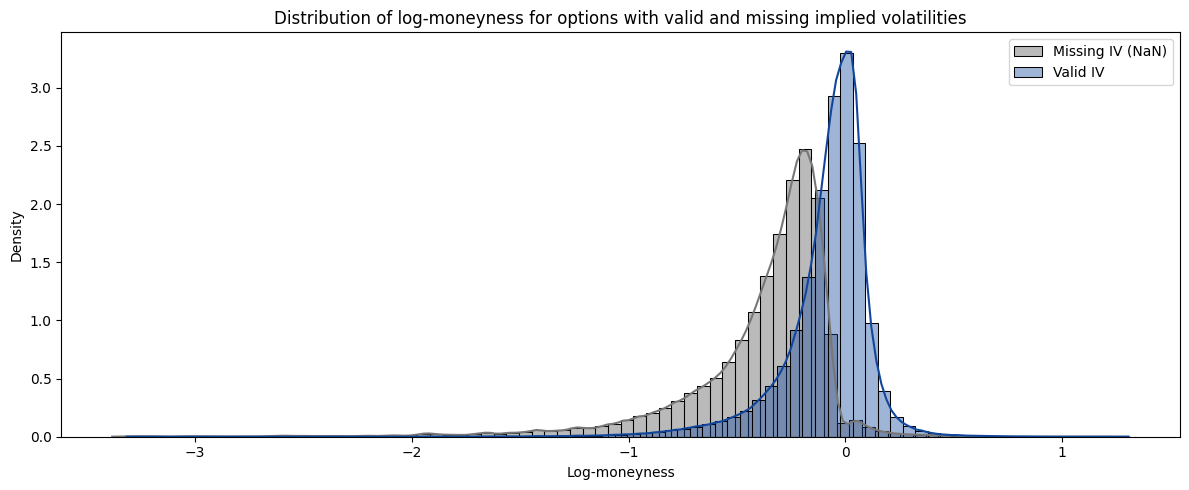


Resumo log_moneyness para opções com IV NaN:


count    2.818040e+06
mean    -3.873298e-01
std      3.588515e-01
min     -3.382974e+00
25%     -4.820187e-01
50%     -2.871039e-01
75%     -1.769954e-01
max      1.309022e+00
Name: log_moneyness, dtype: float64


Resumo log_moneyness para opções com IV válida:


count    8.861810e+06
mean    -8.556761e-02
std      2.063567e-01
min     -3.316042e+00
25%     -1.528437e-01
50%     -4.457658e-02
75%      3.225947e-02
max      1.303233e+00
Name: log_moneyness, dtype: float64

Percentagem de NaNs por ano:
year
2009    24.942805
2010    24.631295
2011    22.591370
2012    25.888480
2013    29.644124
2014    28.427332
2015    25.625752
2016    25.752112
2017    25.280246
2018    18.485506
2019    23.884856
Name: iv_teorica, dtype: float64


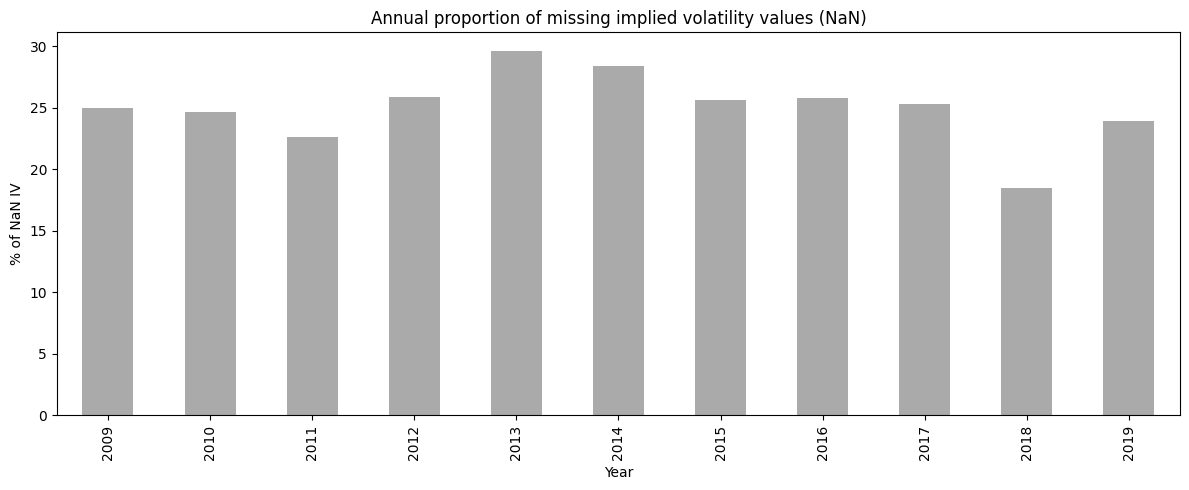

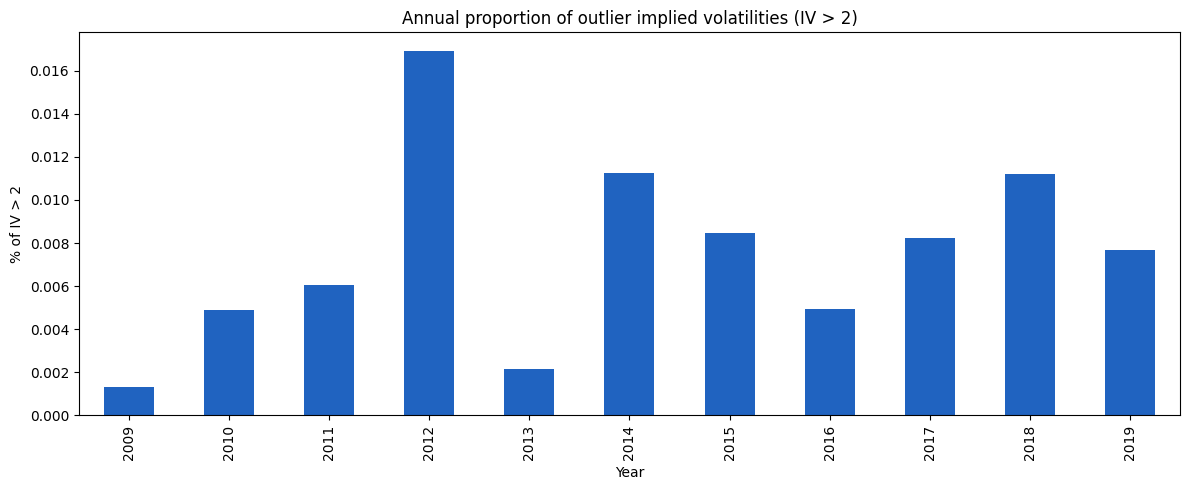

Percentagem de linhas removidas para modelização: 24.14%


In [13]:
# 1. Número e percentagem de NaNs
n_nans = df_7['iv_teorica'].isna().sum()
pct_nans = df_7['iv_teorica'].isna().mean() * 100
print(f"NaN na coluna 'iv_teorica': {n_nans} ({pct_nans:.2f}%)")

# 2. Quantos valores negativos (< 0)
n_negativos = (df_7['iv_teorica'] < 0).sum()
print(f"Valores negativos: {n_negativos}")

# 3. Quantos valores muito elevados (>2, >3, >5)
n_maior_2 = (df_7['iv_teorica'] > 2).sum()
n_maior_3 = (df_7['iv_teorica'] > 3).sum()
n_maior_5 = (df_7['iv_teorica'] > 5).sum()
print(f"Valores >2: {n_maior_2} | >3: {n_maior_3} | >5: {n_maior_5}")

# 4. Estatísticas descritivas (excluindo NaN)
print("\nResumo estatístico (sem NaN):")
display(df_7['iv_teorica'].describe())

# 5. Exemplos de linhas anómalas
# print("\nExemplos de valores negativos:")
# display(df_7[df_7['iv_teorica'] < 0].head())
print("\nExemplos de valores muito elevados (>2):")
display(df_7[df_7['iv_teorica'] > 2].head())

# 6. Analisar NaN
# A. Histograma do log_moneyness para NaN vs não-NaN
plt.figure(figsize=(12,5))
sns.histplot(df_7[df_7['iv_teorica'].isna()]['log_moneyness'], color=COLOR_CINZA1, label='Missing IV (NaN)', kde=True, stat='density', bins=80)
sns.histplot(df_7[~df_7['iv_teorica'].isna()]['log_moneyness'], color=COLOR_AZUL1, label='Valid IV', kde=True, stat='density', bins=80, alpha=0.4)
plt.title("Distribution of log-moneyness for options with valid and missing implied volatilities")
plt.ylabel("Density")
plt.xlabel("Log-moneyness")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(DIR_GRAFICOS, "01_Histograma_log_moneyness_IV_NaN_vs_validas.png"), dpi=150, bbox_inches='tight')
plt.show()

# B. Estatísticas resumo dos NaN e não-NaN
print("\nResumo log_moneyness para opções com IV NaN:")
display(df_7[df_7['iv_teorica'].isna()]['log_moneyness'].describe())
print("\nResumo log_moneyness para opções com IV válida:")
display(df_7[~df_7['iv_teorica'].isna()]['log_moneyness'].describe())

# 7. Análise de distribuição dos NaN e outliers
# A. Distribuição temporal dos NaN

df_7['year'] = pd.to_datetime(df_7['quote_date']).dt.year
nans_por_ano = df_7.groupby('year')['iv_teorica'].apply(lambda x: x.isna().mean()*100)
n_totais_por_ano = df_7.groupby('year').size()
print("Percentagem de NaNs por ano:")
print(nans_por_ano)

ax = nans_por_ano.plot(kind='bar', color=COLOR_CINZA2, figsize=(12,5), title='Annual proportion of missing implied volatility values (NaN)')
plt.ylabel("% of NaN IV")
plt.xlabel("Year")
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(os.path.join(DIR_GRAFICOS, '02_Percentagem_nan_por_ano.png'), dpi=150, bbox_inches='tight')
plt.show()

# B. Distribuição temporal dos outliers (>2)
outlier_por_ano = df_7.groupby('year')['iv_teorica'].apply(lambda x: (x > 2).mean()*100)
ax2 = outlier_por_ano.plot(kind='bar', color=COLOR_AZUL2, figsize=(12,5), title='Annual proportion of outlier implied volatilities (IV > 2)')
plt.ylabel("% of IV > 2")
plt.xlabel("Year")
fig2 = ax2.get_figure()
fig2.tight_layout()
fig2.savefig(os.path.join(DIR_GRAFICOS, '03_Percentagem_outliers_maior_2_por_ano.png'), dpi=150, bbox_inches='tight')
plt.show()

# excluir coluna year do DataFrame
df_7.drop(columns=['year'], inplace=True)   

# 8. Impaxto na exclusão de NaNs e outliers
total = len(df_7)
validos = df_7[(~df_7['iv_teorica'].isna()) & (df_7['iv_teorica'] > 0) & (df_7['iv_teorica'] < 2)]
pct_removido = 100*(1 - len(validos)/total)
print(f"Percentagem de linhas removidas para modelização: {pct_removido:.2f}%")

> **Analysis of NaN and Numerical Outliers in Theoretical IV:**
1. **Numerical Solver Failures (NaN):** Approximately 24% of deep out-of-the-money quotes fail numerical Black-Scholes inversion.
2. **Outlier Filtering (0 < IV <= 2.0):** Excluding non-economic implied volatility above 200% ensures high data quality in the ATM/near-ATM region.


### 13. Filter by Valid Theoretical IV (0 < IV <= 2.0)


In [18]:
# Filtrar df_7 para manter apenas linhas válidas (sem NaN e sem outliers)
df_8 = df_7[(~df_7['iv_teorica'].isna()) & (df_7['iv_teorica'] > 0) & (df_7['iv_teorica'] < 2)].copy()
print(f"Shape final do df_8 (após limpeza): {df_8.shape}")

# Tabela resumo final
tabela_shapes_final = pd.DataFrame(shapes_resumo + [["Final", df_8.shape[0], df_8.shape[1]]], columns=["Passo", "N_linhas", "N_colunas"])
print("Shapes finais do DataFrame:")
display(tabela_shapes_final)

# Resumo da Tabela df_7(antes de remover NaNs e outliers) - numero e percentagem de Calls e Puts
pct_calls_7 = df_7[df_7['option_is_call'] == 1].shape[0] / df_7.shape[0] * 100
pct_puts_7 = df_7[df_7['option_is_call'] == 0].shape[0] / df_7.shape[0] * 100
print(f"Percentagem de Calls em df_7: {pct_calls_7:.2f}% | Percentagem de Puts em df_7: {pct_puts_7:.2f}%")
tabela_estrutura_7 = pd.DataFrame({
    "Tipo de Opção": ["Calls", "Puts"],
    "Número de Opções": [df_7[df_7['option_is_call'] == 1].shape[0], df_7[df_7['option_is_call'] == 0].shape[0]],
    "Percentagem (%)": [pct_calls_7, pct_puts_7]
})
print("Estrutura do universo antes de remover NaNs e outliers (df_7):")
display(tabela_estrutura_7)

# Dataframe final
df_8.head()

#Verificar número e percentagem de Calls e de Puts no dataframe final (Tabela Resumo)
pct_calls = df_8[df_8['option_is_call'] == 1].shape[0] / df_8.shape[0] * 100
pct_puts = df_8[df_8['option_is_call'] == 0].shape[0] / df_8.shape[0] * 100
print(f"Percentagem de Calls: {pct_calls:.2f}% | Percentagem de Puts: {pct_puts:.2f}%")

tabela_estrutura = pd.DataFrame({
    "Tipo de Opção": ["Calls", "Puts"],
    "Número de Opções": [df_8[df_8['option_is_call'] == 1].shape[0], df_8[df_8['option_is_call'] == 0].shape[0]],
    "Percentagem (%)": [pct_calls, pct_puts]
})
print("Estrutura do universo de modelização:")
display(tabela_estrutura)

#Estatísticas descritivas da iv_teorica
print("Estatísticas descritivas da iv_teorica:")
display(df_8['iv_teorica'].describe())

Shape final do df_8 (após limpeza): (8860820, 11)
Shapes finais do DataFrame:


,Passo,N_linhas,N_colunas
0,Original,15144974,17
1,Liquidez,13819247,17
2,Maturidade,11763998,17
3,Mercado Fechado,11679850,17
4,Final,8860820,11


Percentagem de Calls em df_7: 50.83% | Percentagem de Puts em df_7: 49.17%
Estrutura do universo antes de remover NaNs e outliers (df_7):


,Tipo de Opção,Número de Opções,Percentagem (%)
0,Calls,5937233,50.833127
1,Puts,5742617,49.166873


Percentagem de Calls: 35.94% | Percentagem de Puts: 64.06%
Estrutura do universo de modelização:


,Tipo de Opção,Número de Opções,Percentagem (%)
0,Calls,3184554,35.939721
1,Puts,5676266,64.060279


Estatísticas descritivas da iv_teorica:


count    8.860820e+06
mean     2.185875e-01
std      1.237588e-01
min      3.520494e-04
25%      1.320822e-01
50%      1.857185e-01
75%      2.739695e-01
max      1.998656e+00
Name: iv_teorica, dtype: float64

### 14. 3D Surface & Heatmap Visualization of Theoretical IV


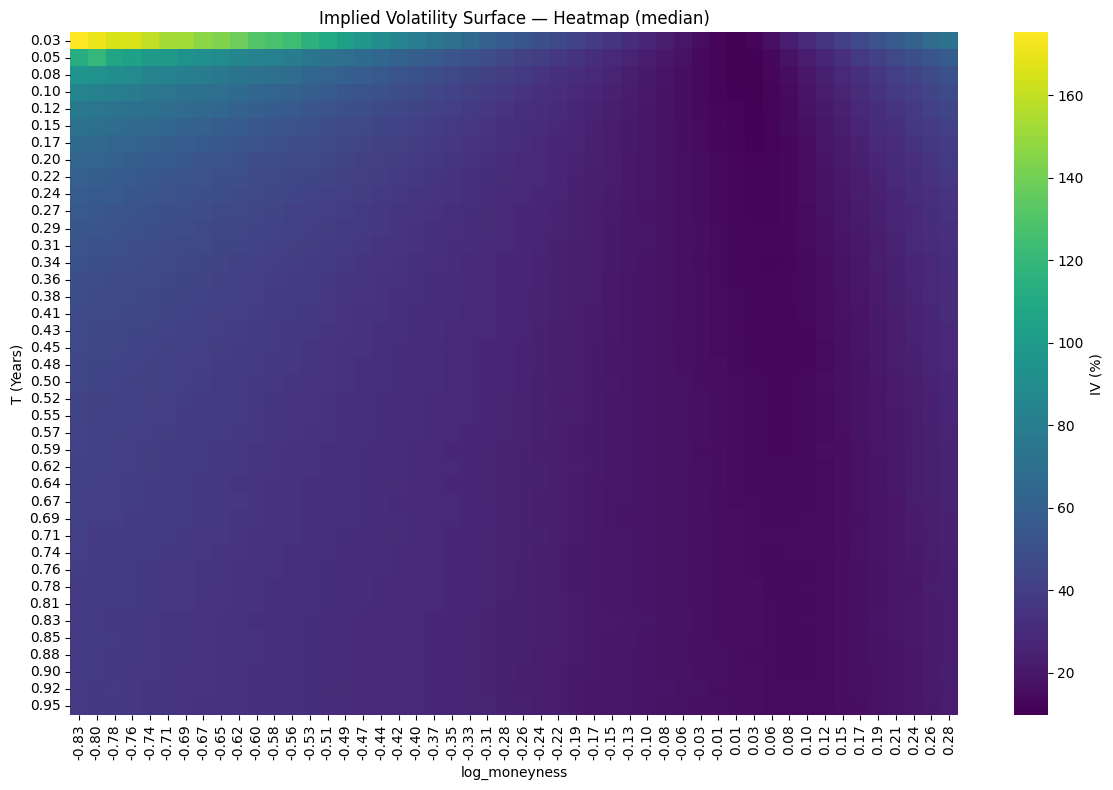

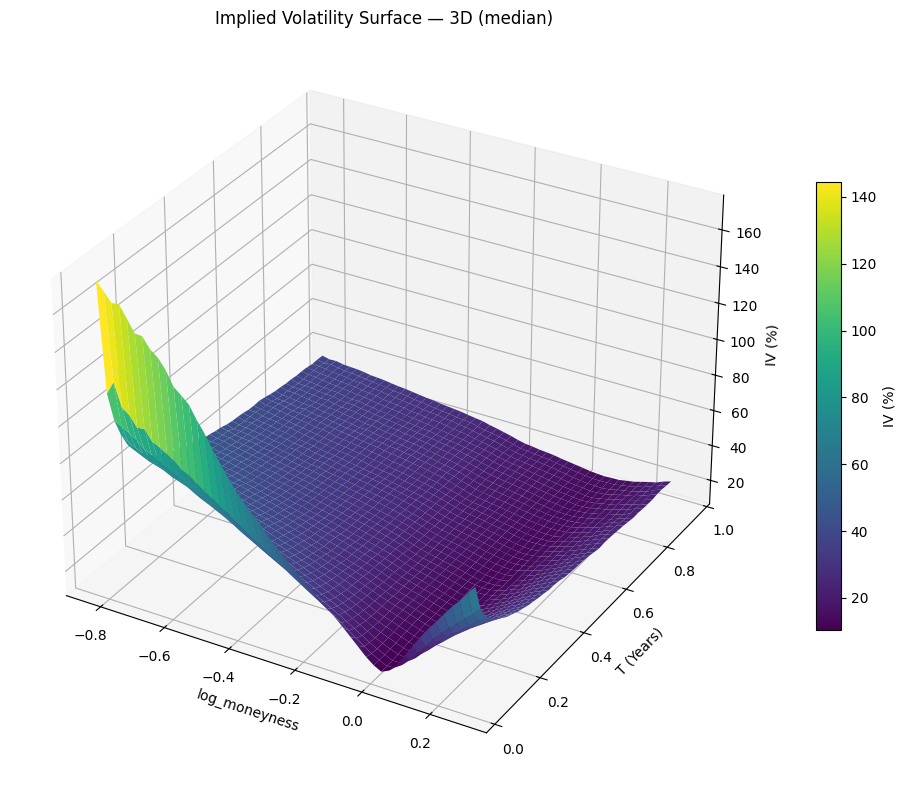

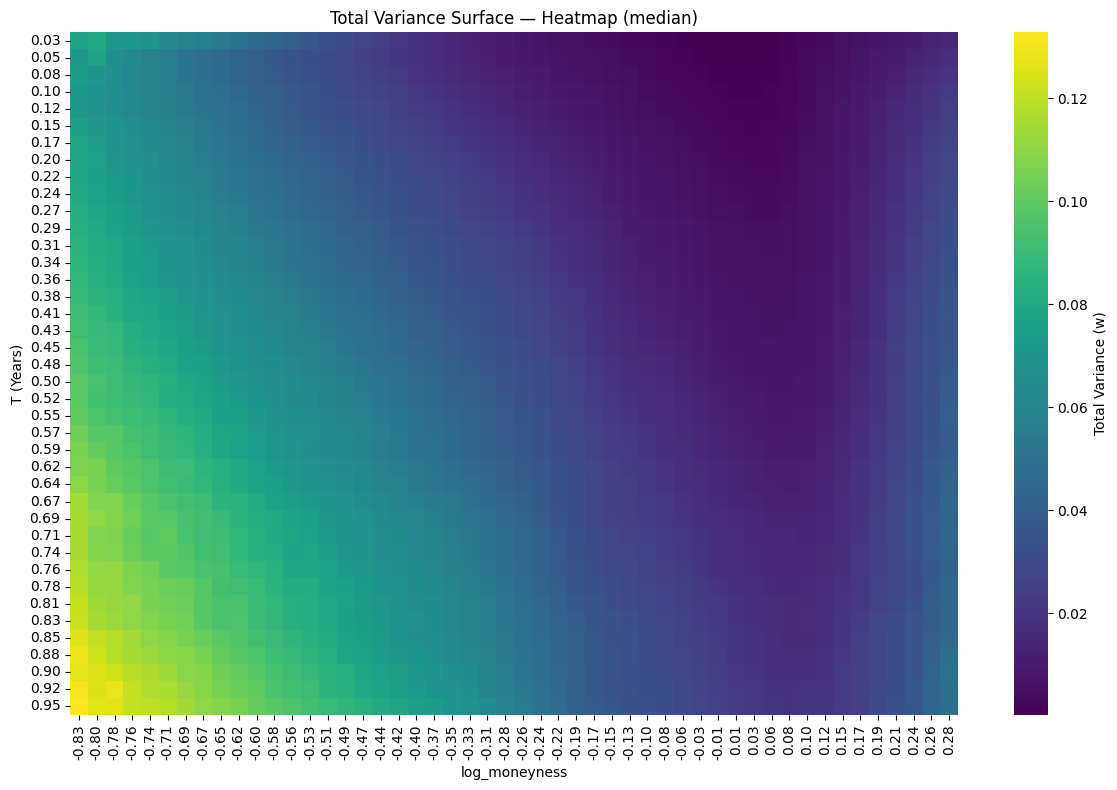

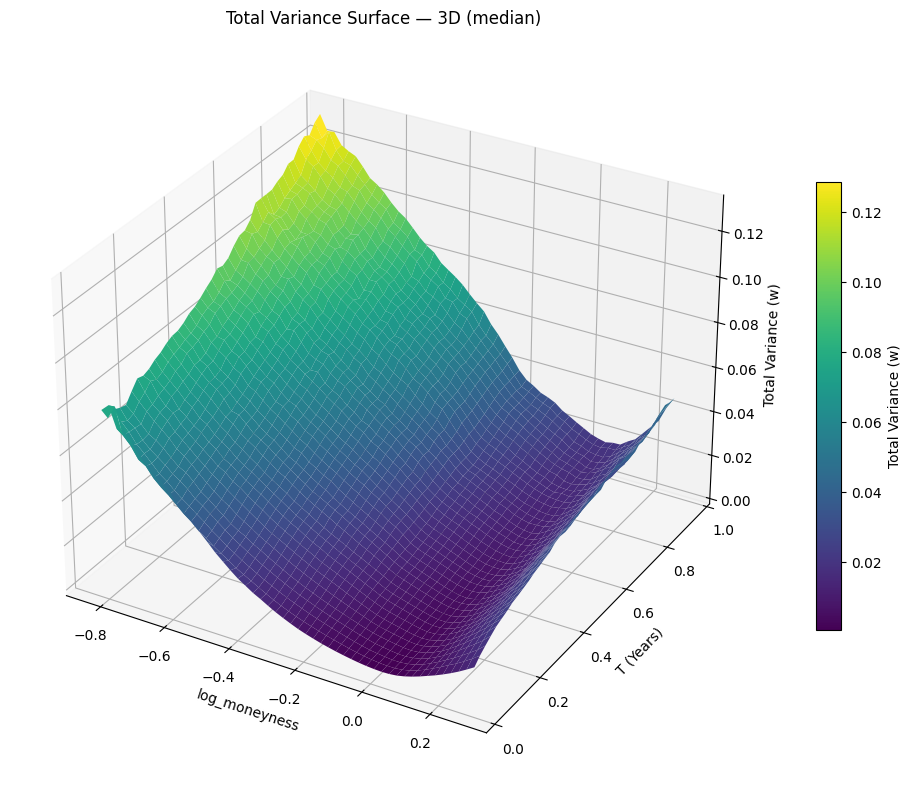

In [15]:
# 1) Superfície teórica “raw”
plot_ivs_and_variance_surfaces(
    df_8,
    x_col="log_moneyness", y_col="T", z_col="iv_teorica",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="teorica"
)

### 15. Observation Count & Split Planning


In [16]:
# 1) contagem diária
daily = (
    df_8.assign(quote_date=pd.to_datetime(df_8["quote_date"], errors="coerce"))
        .groupby("quote_date").size().sort_index()
)

total_rows = int(daily.sum())
cum_rows   = daily.cumsum()
n_days     = len(daily)

# Splits a testar (train/test)
train_fracs = [0.70, 0.75, 0.80, 0.85, 0.90]

# ===== A) Tabela por LINHAS =====
rows_records = []
for tr in train_fracs:
    target_train = int(np.floor(tr * total_rows))
    idx = np.searchsorted(cum_rows.values, target_train, side="left")
    test_start = daily.index[min(idx, len(daily)-1)]

    train_rows = int(daily.loc[daily.index < test_start].sum())
    test_rows  = total_rows - train_rows
    train_days = int((daily.index < test_start).sum())
    test_days  = int((daily.index >= test_start).sum())

    rows_records.append({
        "Split (train/test)": f"{int(tr*100)}/{int((1-tr)*100)}",
        "test_start": test_start.date(),
        "train_rows": train_rows,
        "test_rows":  test_rows,
        "train_days": train_days,
        "test_days":  test_days
    })

res_rows = pd.DataFrame(rows_records, columns=[
    "Split (train/test)", "test_start", "train_rows", "test_rows", "train_days", "test_days"
])
print("=== Corte por LINHAS ===")
print(res_rows.to_string(index=False))

# ===== B) Tabela por DATAS (DIAS) =====
days_records = []
for tr_frac in train_fracs:
    test_days_target = max(1, int(round((1 - tr_frac) * n_days)))  # nº de DIAS para o teste
    test_start = daily.index[-test_days_target]

    train_days = n_days - test_days_target
    test_days  = test_days_target
    train_rows = int(daily.loc[daily.index < test_start].sum())
    test_rows  = int(daily.loc[daily.index >= test_start].sum())

    days_records.append({
        "Split (train/test)": f"{int(tr_frac*100)}/{int((1-tr_frac)*100)}",
        "test_start": test_start.date(),
        "train_days": train_days,
        "test_days":  test_days,
        "train_rows": train_rows,
        "test_rows":  test_rows,
        "train_frac_rows": train_rows / total_rows,  # útil comparar que % de LINHAS dá este corte por DIAS
        "test_frac_rows":  test_rows  / total_rows
    })

res_days = pd.DataFrame(days_records)
res_days_fmt = res_days.copy()
res_days_fmt["train_frac_rows"]  = (res_days_fmt["train_frac_rows"]*100).round(2).astype(str) + "%"
res_days_fmt["test_frac_rows"]   = (res_days_fmt["test_frac_rows"]*100).round(2).astype(str) + "%"

print("\n=== Corte por DATAS (DIAS) ===")
print(res_days_fmt.to_string(index=False))

=== Corte por LINHAS ===
Split (train/test) test_start  train_rows  test_rows  train_days  test_days
             70/30 2018-02-12     6199216    2661604        2275        302
             75/25 2018-04-24     6643589    2217231        2324        253
             80/19 2018-07-10     7084040    1776780        2377        200
             85/15 2018-09-24     7524477    1336343        2430        147
              90/9 2018-11-30     7967225     893595        2476        101

=== Corte por DATAS (DIAS) ===
Split (train/test) test_start  train_days  test_days  train_rows  test_rows train_frac_rows test_frac_rows
             70/30 2016-03-24        1804        773     3787061    5073759          42.74%         57.26%
             75/25 2016-09-28        1933        644     4310794    4550026          48.65%         51.35%
             80/19 2017-04-06        2062        515     4913117    3947703          55.45%         44.55%
             85/15 2017-10-10        2190        387     56

### 16. Construct Temporal Partitions with Embargo Gaps & Export


In [17]:
# ================== PARÂMETROS (tudo configurável) ==================
TEST_START   = "2018-10-01"   # início do teste puro (snap calendário)
TEST_END     = "2019-04-30"   # fim do teste puro (None -> usa tudo até ao fim dos dados)

TUNE_START   = "2018-01-02"   # inner_tunning: início (Q1 2018)
TUNE_END     = None           # se None, termina no dia útil ANTES do embargo externo
                              # (na prática, sextas antes de 2018-09-24 para embargo=5)

TRAIN_LAST_Y = "2017-12-31"   # inner_train vai até 2017 (inclusive), exceto embargo interno

EMBARGO_INTERNO_BDAYS = 3     # últimos N dias úteis de 2017 (fim do inner_train)
EMBARGO_EXTERNO_BDAYS = 5     # últimos N dias úteis ANTES de TEST_START (fim do train_full)

# ================== BASE ==================
import pandas as pd, numpy as np, json, os

df_base = df_8.copy()
if "quote_date" not in df_base.columns:
    raise ValueError("Coluna 'quote_date' não existe no DataFrame base.")

df_base = df_base.copy()
df_base["quote_date"] = pd.to_datetime(df_base["quote_date"], errors="coerce")
df_base = df_base.dropna(subset=["quote_date"]).sort_values("quote_date")
dias = pd.DatetimeIndex(df_base["quote_date"].drop_duplicates().sort_values())

TEST_START = pd.Timestamp(TEST_START)
TEST_END   = pd.Timestamp(TEST_END) if TEST_END is not None else dias.max()

TUNE_START = pd.Timestamp(TUNE_START)
TRAIN_LAST_Y = pd.Timestamp(TRAIN_LAST_Y)  # 2017-12-31

# ================== EMBARGOS ==================
# Interno: últimos N dias úteis de 2017
dias_2017 = dias[(dias.year == 2017)]
if len(dias_2017) == 0:
    raise ValueError("Não há dias de mercado em 2017 no DataFrame.")
embargo_int_dias = set()
if EMBARGO_INTERNO_BDAYS > 0:
    take = min(EMBARGO_INTERNO_BDAYS, len(dias_2017))
    embargo_int_dias = set(dias_2017[-take:].to_list())

# Externo: últimos N dias úteis ANTES do TEST_START
dias_antes_teste = dias[dias < TEST_START]
embargo_ext_dias = set()
if EMBARGO_EXTERNO_BDAYS > 0 and len(dias_antes_teste) > 0:
    take = min(EMBARGO_EXTERNO_BDAYS, len(dias_antes_teste))
    embargo_ext_dias = set(dias_antes_teste[-take:].to_list())

# Se TUNE_END for None, termina no dia útil anterior ao início do embargo externo
if TUNE_END is None:
    if len(embargo_ext_dias) == 0:
        # fallback: véspera do TEST_START
        from pandas.tseries.offsets import BDay
        TUNE_END = TEST_START - BDay(1)
    else:
        embargo_ext_inicio = min(embargo_ext_dias)
        from pandas.tseries.offsets import BDay
        TUNE_END = embargo_ext_inicio - BDay(1)
else:
    TUNE_END = pd.Timestamp(TUNE_END)

# Guard-rails
if not (dias.min() <= TUNE_START <= dias.max()):
    raise ValueError("TUNE_START fora do intervalo de datas dos dados.")
if not (dias.min() <= TUNE_END <= dias.max()):
    raise ValueError("TUNE_END fora do intervalo de datas dos dados.")
if not (dias.min() <= TEST_START <= dias.max()):
    raise ValueError("TEST_START fora do intervalo de datas dos dados.")
if TEST_END < TEST_START:
    raise ValueError("TEST_END anterior a TEST_START.")

# ================== AMOSTRAS ==================
d = pd.DatetimeIndex(df_base["quote_date"])

# inner_train: tudo <= 2017-12-31, excluindo embargo interno (no fim de 2017)
mask_inner_train   = (d <= TRAIN_LAST_Y) & (~d.isin(embargo_int_dias))

# inner_tunning: 2018 Q1–Q3 (TUNE_START..TUNE_END), garantidamente antes do embargo externo
mask_inner_tunning = (d >= TUNE_START) & (d <= TUNE_END) & (~d.isin(embargo_ext_dias))

# train_full: tudo < TEST_START, excluindo embargos (interno 2017 e externo antes do teste)
mask_train_full    = (d < TEST_START) & (~d.isin(embargo_int_dias)) & (~d.isin(embargo_ext_dias))

# test_puro: [TEST_START .. TEST_END]
mask_test_puro     = (d >= TEST_START) & (d <= TEST_END)

df_inner_train   = df_base.loc[mask_inner_train].copy()
df_inner_tunning = df_base.loc[mask_inner_tunning].copy()
df_train_full    = df_base.loc[mask_train_full].copy()
df_test_puro     = df_base.loc[mask_test_puro].copy()

# ================== GUARDAR ==================
df_inner_train.to_parquet(ficheiro_inner_train, index=False)
df_inner_tunning.to_parquet(ficheiro_inner_tunning, index=False)
df_train_full.to_parquet(ficheiro_train_full, index=False)
df_test_puro.to_parquet(ficheiro_test_puro, index=False)

if not os.path.exists(ficheiro_universo):
    df_base.to_parquet(ficheiro_universo, index=False)

# ================== META (resumo + percentagens) ==================
total_rows       = len(df_base)
train_full_rows  = len(df_train_full)
inner_train_rows = len(df_inner_train)
inner_tune_rows  = len(df_inner_tunning)
test_rows        = len(df_test_puro)

def bloco_meta(df):
    return {
        "inicio": str(df["quote_date"].min().date()) if not df.empty else None,
        "fim":    str(df["quote_date"].max().date()) if not df.empty else None,
        "n_obs":  int(len(df)),
        "n_dias": int(df["quote_date"].nunique()),
        "pct_total": f"{100*len(df)/total_rows:.2f}%"
    }

# atualiza meta
meta = {}
meta = {
    "config": meta.get("config", {}),
    "periodo_total": {
        "min": str(df_base["quote_date"].min().date()),
        "max": str(df_base["quote_date"].max().date()),
        "n_total_rows": int(total_rows),
        "n_total_days": int(df_base["quote_date"].nunique())
    },
    "train_full":   bloco_meta(df_train_full),
    "test_puro":    bloco_meta(df_test_puro),
    "inner_train":  bloco_meta(df_inner_train),
    "inner_tunning":bloco_meta(df_inner_tunning),
    "embargo":      meta.get("embargo", {}),
    "paths":        meta.get("paths", {})
}

# acrescenta percentagens relativas AO TREINO para os blocos internos
meta["inner_train"]["pct_of_train_full"]   = (f"{100*inner_train_rows/train_full_rows:.2f}%"
                                              if train_full_rows else "0.00%")
meta["inner_tunning"]["pct_of_train_full"] = (f"{100*inner_tune_rows/train_full_rows:.2f}%"
                                              if train_full_rows else "0.00%")

# salva meta
with open(ficheiro_meta_splits, "w") as f:
    json.dump(meta, f, indent=2)

# ================== RESUMO EM TABELA ==================
resumo = pd.DataFrame.from_records([
    ["train_full",    meta["train_full"]["inicio"],    meta["train_full"]["fim"],
     train_full_rows, meta["train_full"]["n_dias"],    meta["train_full"]["pct_total"], ""],
    ["test_puro",     meta["test_puro"]["inicio"],     meta["test_puro"]["fim"],
     test_rows,       meta["test_puro"]["n_dias"],     meta["test_puro"]["pct_total"], ""],
    ["inner_train",   meta["inner_train"]["inicio"],   meta["inner_train"]["fim"],
     inner_train_rows,meta["inner_train"]["n_dias"],   meta["inner_train"]["pct_total"],
     meta["inner_train"]["pct_of_train_full"]],
    ["inner_tunning", meta["inner_tunning"]["inicio"], meta["inner_tunning"]["fim"],
     inner_tune_rows, meta["inner_tunning"]["n_dias"], meta["inner_tunning"]["pct_total"],
     meta["inner_tunning"]["pct_of_train_full"]],
], columns=["amostra", "inicio", "fim", "n_obs", "n_dias",
            "pct_total", "pct_de_train_full"])

print(resumo.to_string(index=False))

      amostra     inicio        fim   n_obs  n_dias pct_total pct_de_train_full
   train_full 2009-01-02 2018-09-21 7505238    2427    84.70%                  
    test_puro 2018-10-01 2019-04-30 1292514     142    14.59%                  
  inner_train 2009-01-02 2017-12-26 5970843    2244    67.38%            79.56%
inner_tunning 2018-01-02 2018-09-21 1534395     183    17.32%            20.44%
